In [4]:
import tomllib

import matplotlib.pyplot as plt
import numpy as np
import plt_config  # noqa: F401
import seaborn as sns

# Visualizing the eigenvalues from empirical observability gramian

In [5]:
try:
    diag_values = np.load("../scripts/saved_variables/module1/diag_values_01.npy")
    eig_values = np.load("../scripts/saved_variables/module1/eig_values_01.npy")
except FileNotFoundError:
    print("Run 01_Observability_Analysis.py")

In [6]:
with open("../config.toml", "rb") as f:
    cfg = tomllib.load(f)

curr_module = "01"
num_patients = cfg[curr_module]["num_patients"]
threshold = cfg[curr_module]["threshold"]
percent_states_over_threshold = (
    100 * (eig_values > threshold).sum() / len(eig_values.flatten())
)
print("Percent of eigenvalues over threshold: ", percent_states_over_threshold)

Percent of eigenvalues over threshold:  72.91666666666667


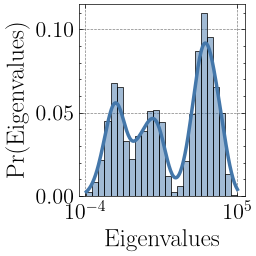

In [7]:
fig, ax = plt.subplots(figsize=(2.55, 2.55))
sns.histplot(
    eig_values.flatten(),
    stat="probability",
    bins=25,
    ax=ax,
    log_scale=True,
    legend=False,
    kde=True,
)
# ax.axvline(threshold, color="red", linestyle=":", linewidth=2)
# ax.text(
#     threshold,
#     ax.get_ylim()[1] * 0.90,
#     r"$10^{-1}$",
#     color="red",
#     rotation=90,
#     va="top",
#     ha="center",
#     backgroundcolor="white",
# )
ax.set_xlabel("Eigenvalues")
ax.set_ylabel("Pr(Eigenvalues)")
fig.savefig("figures/5_3.pdf", format="pdf")

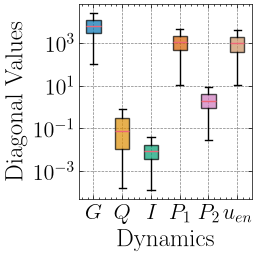

In [8]:
states = [
    r"$G$",
    r"$Q$",
    r"$I$",
    r"$P_1$",
    r"$P_2$",
    r"$u_{en}$",
]
palette = sns.color_palette("colorblind", len(states))
fig, ax = plt.subplots(figsize=(2.55, 2.55))
bp = ax.boxplot(diag_values, tick_labels=states, patch_artist=True, showfliers=False)
ax.set_yscale("log")
ax.set_xlabel("Dynamics")
ax.set_ylabel("Diagonal Values")
for patch, color in zip(bp["boxes"], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
fig.savefig("figures/5_7.pdf", format="pdf")

In [9]:
print("Medians: \n", np.percentile(diag_values, 50, axis=0))
print(
    "IQR: \n",
    np.percentile(diag_values, 75, axis=0) - np.percentile(diag_values, 25, axis=0),
)

Medians: 
 [6.15974842e+03 7.75013611e-02 8.72055626e-03 1.04415484e+03
 1.97532637e+00 9.60587033e+02]
IQR: 
 [8.70069389e+03 2.99872350e-01 1.34051918e-02 1.60349972e+03
 3.08489571e+00 1.46665293e+03]
